### Configure environment

In [ ]:
from fabrictestbed_extensions.fablib.fablib import FablibManager as fablib_manager
fablib = fablib_manager()
conf = fablib.show_config()

### Define configuration for this experiment

In [ ]:
slice_name="dualpi2-analysis-motivation" + fablib.get_bastion_username()

node_conf = [
 {'name': "tx_L4S",    'cores': 4, 'ram': 32, 'disk': 20, 'image': 'default_ubuntu_22', 'packages': ['iperf3', 'net-tools', 'moreutils','python3']},
 {'name': "tx_legacy",    'cores': 4, 'ram': 32, 'disk': 20, 'image': 'default_ubuntu_22', 'packages': ['iperf3', 'net-tools', 'moreutils','python3']},
 {'name': "router", 'cores': 4, 'ram': 32, 'disk': 20, 'image': 'default_ubuntu_22', 'packages': ['iperf3', 'net-tools', 'moreutils','python3']},
 {'name': "delay", 'cores': 4, 'ram': 32, 'disk': 20, 'image': 'default_ubuntu_22', 'packages': ['iperf3', 'net-tools', 'moreutils','python3']},
 {'name': "rx_L4S",    'cores': 4, 'ram': 32, 'disk': 20, 'image': 'default_ubuntu_22', 'packages': ['iperf3', 'net-tools', 'moreutils','python3']},
 {'name': "rx_legacy",    'cores': 4, 'ram': 32, 'disk': 20, 'image': 'default_ubuntu_22', 'packages': ['iperf3', 'net-tools', 'moreutils','python3']}
]
net_conf = [
 {"name": "net-tx", "subnet": "10.0.0.0/24", "nodes": [{"name": "tx_L4S",   "addr": "10.0.0.100"}, {"name": "tx_legacy",   "addr": "10.0.0.101"}, {"name": "delay", "addr": "10.0.0.2"}]},
 {"name": "net-delay-router", "subnet": "10.0.2.0/24", "nodes": [{"name": "delay",   "addr": "10.0.2.2"}, {"name": "router", "addr": "10.0.2.1"}]},
 {"name": "net-rx", "subnet": "10.0.5.0/24", "nodes": [{"name": "router",   "addr": "10.0.5.1"}, {"name": "rx_L4S", "addr": "10.0.5.100"}, {"name": "rx_legacy", "addr": "10.0.5.101"}]}

]
route_conf = [
 {"addr": "10.0.5.0/24", "gw": "10.0.0.2", "nodes": ["tx_L4S", "tx_legacy"]},
 {"addr": "10.0.5.0/24", "gw": "10.0.2.1", "nodes": ["delay"]},

 {"addr": "10.0.0.0/24", "gw": "10.0.5.1", "nodes": ["rx_L4S", "rx_legacy"]},
 {"addr": "10.0.0.0/24", "gw": "10.0.2.2", "nodes": ["router"]}

]
exp_conf = {'cores': sum([ n['cores'] for n in node_conf]), 'nic': sum([len(n['nodes']) for n in net_conf]) }

### Reserve resources

Now, we are ready to reserve resources!

First, make sure you don’t already have a slice with this name:

In [ ]:
try:
    slice = fablib.get_slice(slice_name)
    print("You already have a slice by this name!")
    print("If you previously reserved resources, skip to the 'log in to resources' section.")
except:
    print("You don't have a slice named %s yet." % slice_name)
    print("Continue to the next step to make one.")
    slice = fablib.new_slice(name=slice_name)

User: fbs6417@nyu.edu bastion key is valid!
Configuration is valid
You already have a slice by this name!
If you previously reserved resources, skip to the 'log in to resources' section.


We will select a random site that has sufficient resources for our experiment:

In [ ]:
while True:
    site_name = fablib.get_random_site()
    if ( (fablib.resources.get_core_available(site_name) > 1.2*exp_conf['cores']) and
        (fablib.resources.get_component_available(site_name, 'SharedNIC-ConnectX-6') > 1.2**exp_conf['nic']) ):
        break

fablib.show_site(site_name)

Then we will add hosts and network segments:

In [ ]:
# this cell sets up the nodes
for n in node_conf:
    slice.add_node(name=n['name'], site=site_name,
                   cores=n['cores'],
                   ram=n['ram'],
                   disk=n['disk'],
                   image=n['image'])

In [ ]:
# this cell sets up the network segments
for n in net_conf:
    ifaces = [slice.get_node(node["name"]).add_component(model="NIC_Basic",
                                                 name=n["name"]).get_interfaces()[0] for node in n['nodes'] ]
    slice.add_l2network(name=n["name"], type='L2Bridge', interfaces=ifaces)

The following cell submits our request to the FABRIC site. The output of this cell will update automatically as the status of our request changes.

-   While it is being prepared, the “State” of the slice will appear as “Configuring”.
-   When it is ready, the “State” of the slice will change to “StableOK”.

You may prefer to walk away and come back in a few minutes (for simple slices) or a few tens of minutes (for more complicated slices with many resources).

In [ ]:
slice.submit()

In [ ]:
slice.get_state()
slice.wait_ssh(progress=True)

Waiting for slice . Slice state: StableOK
Waiting for ssh in slice . ssh successful


True

### Extend your slice

If you don’t plan to finish an experiment in one day, you can extend your slice. The following cell extends your reservation for 7 days.

In [ ]:
from datetime import datetime
from datetime import timezone
from datetime import timedelta

# Set end date to 7 days from now
end_date = (datetime.now(timezone.utc) + timedelta(days=7)).strftime("%Y-%m-%d %H:%M:%S %z")
slice.renew(end_date)

## We have reserved our slice and now we need to configure our nodes. ##

### Configure Experiment - Prague Kernel Installation

#### Install Prague kernel to all the nodes. Configure DualPI2 on the router. ####

#### 6.6 Kernel

In [ ]:
node_names = ["router", "tx_L4S", "rx_L4S"]

for node_name in node_names:
    node = slice.get_node(name=node_name)

    # Download and unzip the kernel package
    node.execute("wget https://github.com/L4STeam/linux/releases/download/l4steam-6.6.y-build/l4s-l4steam-6.6.y.zip")
    node.execute("sudo apt install -y unzip")
    node.execute("unzip l4s-l4steam-6.6.y.zip")

    # Install the kernel packages and update GRUB
    node.execute("sudo dpkg --install debian_build/*")
    node.execute("sudo update-grub")
    node.execute("sudo reboot")

# Wait for nodes to come back up
slice.wait_ssh(progress=True)

# Check kernel versions
for node_name in node_names:
    node = slice.get_node(name=node_name)
    node.execute("hostname; uname -a")

### Configure Experiment - BBRv2 Kernel Installation - Do this if you want to use CUBIC or BBRv2 on the classic senders.

Not needed for this experiment: CUBIC and BBRv1 run on the Linux 6.4.0 kernel installed in the next section.

#### Install BBRv2 kernel to classic senders and receivers. ####

In [ ]:
pkg_list = ['linux-headers-5.13.12_5.13.12-2_amd64.deb',
            'linux-libc-dev_5.13.12-2_amd64.deb',
            'linux-image-5.13.12_5.13.12-2_amd64.deb']

cmd_BBRv2 = """sudo grub-set-default "Advanced options for Ubuntu>Ubuntu, with Linux 5.13.12"
sudo grub-mkconfig -o /boot/grub/grub.cfg
sudo sed -i 's/^GRUB_DEFAULT=.*/GRUB_DEFAULT=saved/' /etc/default/grub
sudo update-grub
sudo reboot"""


for pkg in pkg_list:
        slice.get_node(name="tx_legacy").execute("wget https://raw.githubusercontent.com/sdatta97/imcbbrrepro/main/setup/{packet}".format(packet=pkg))
        slice.get_node(name="rx_legacy").execute("wget https://raw.githubusercontent.com/sdatta97/imcbbrrepro/main/setup/{packet}".format(packet=pkg))

slice.get_node(name="tx_legacy").execute("sudo dpkg -i  *.deb")
slice.get_node(name="tx_legacy").execute(cmd_BBRv2)

slice.get_node(name="rx_legacy").execute("sudo dpkg -i  *.deb")
slice.get_node(name="rx_legacy").execute(cmd_BBRv2)

### Configure Experiment - Kernel Installation - Linux 6.4.0

This experiment needs this kernel on `tx_legacy` and `rx_legacy` (CUBIC, and BBRv1 as `bbr1`).

In [ ]:
pkg_list = ['linux-headers-6.4.0+_6.4.0-g6e321d1c986a-5_amd64.deb',
            'linux-image-6.4.0+_6.4.0-g6e321d1c986a-5_amd64.deb',
            'linux-libc-dev_6.4.0-g6e321d1c986a-5_amd64.deb']

cmd_BBRv3 ="""sudo grub-set-default "Advanced options for Ubuntu>Ubuntu, with Linux 6.4.0"
sudo grub-mkconfig -o /boot/grub/grub.cfg
sudo sed -i 's/^GRUB_DEFAULT=.*/GRUB_DEFAULT=saved/' /etc/default/grub
sudo update-grub
sudo reboot"""

for pkg in pkg_list:
    slice.get_node(name="tx_legacy").execute("wget https://github.com/ashutoshs25/bbrv3-kernel/raw/main/{packet}".format(packet=pkg))
    slice.get_node(name="rx_legacy").execute("wget https://github.com/ashutoshs25/bbrv3-kernel/raw/main/{packet}".format(packet=pkg))

slice.get_node(name="tx_legacy").execute("sudo dpkg -i  *.deb")
slice.get_node(name="tx_legacy").execute(cmd_BBRv3)

slice.get_node(name="rx_legacy").execute("sudo dpkg -i  *.deb")
slice.get_node(name="rx_legacy").execute(cmd_BBRv3)

### Check kernel and ip versions of the nodes to be sure. ###

In [ ]:
slice.get_node(name="tx_legacy").execute("sudo ip -V")
slice.get_node(name="rx_legacy").execute("sudo ip -V")

In [ ]:
slice.get_node(name="tx_L4S").execute("ip -V")

In [ ]:
for node in slice.get_nodes():
    # check kernel version
    node.execute("hostname; uname -a")

### Configure resources

Next, we will configure the resources so they are ready to use.

In [ ]:
slice = fablib.get_slice(name=slice_name)

In [ ]:
# install packages
# this will take a while and will run in background while you do other steps
for n in node_conf:
    if len(n['packages']):
        node = slice.get_node(n['name'])
        pkg = " ".join(n['packages'])
        node.execute_thread("sudo apt update; sudo apt -y install %s" % pkg)

In [ ]:
# bring interfaces up and either assign an address (if there is one) or flush address
from ipaddress import ip_address, IPv4Address, IPv4Network

for net in net_conf:
    for n in net['nodes']:
        if_name = n['name'] + '-' + net['name'] + '-p1'
        iface = slice.get_interface(if_name)
        iface.ip_link_up()
        if n['addr']:
            iface.ip_addr_add(addr=n['addr'], subnet=IPv4Network(net['subnet']))
        else:
            iface.get_node().execute("sudo ip addr flush dev %s"  % iface.get_device_name())

In [ ]:
# prepare a "hosts" file that has names and addresses of every node
hosts_txt = [ "%s\t%s" % ( n['addr'], n['name'] ) for net in net_conf  for n in net['nodes'] if type(n) is dict and n['addr']]
for n in slice.get_nodes():
    for h in hosts_txt:
        n.execute("echo %s | sudo tee -a /etc/hosts" % h)

In [ ]:
# enable IPv4 forwarding on all nodes
for n in slice.get_nodes():
    n.execute("sudo sysctl -w net.ipv4.ip_forward=1")

In [ ]:
# set up static routes
for rt in route_conf:
    for n in rt['nodes']:
        slice.get_node(name=n).ip_route_add(subnet=IPv4Network(rt['addr']), gateway=rt['gw'])

In [ ]:
# turn off segmentation offload on interfaces
for iface in slice.get_interfaces():
    iface_name = iface.get_device_name()
    n = iface.get_node()
    offloads = ["gro", "lro", "gso", "tso"]
    for offload in offloads:
        n.execute("sudo ethtool -K %s %s off" % (iface_name, offload))

### Draw the network topology

The following cell will draw the network topology, for your reference. The interface name and addresses of each experiment interface will be shown on the drawing.

In [ ]:
l2_nets = [(n.get_name(), {'color': 'lavender'}) for n in slice.get_l2networks() ]
l3_nets = [(n.get_name(), {'color': 'pink'}) for n in slice.get_l3networks() ]
hosts   =   [(n.get_name(), {'color': 'lightblue'}) for n in slice.get_nodes()]
nodes = l2_nets + l3_nets + hosts
ifaces = [iface.toDict() for iface in slice.get_interfaces()]
edges = [(iface['network'], iface['node'],
          {'label': iface['physical_dev'] + '\n' + iface['ip_addr'] + '\n' + iface['mac']}) for iface in ifaces]

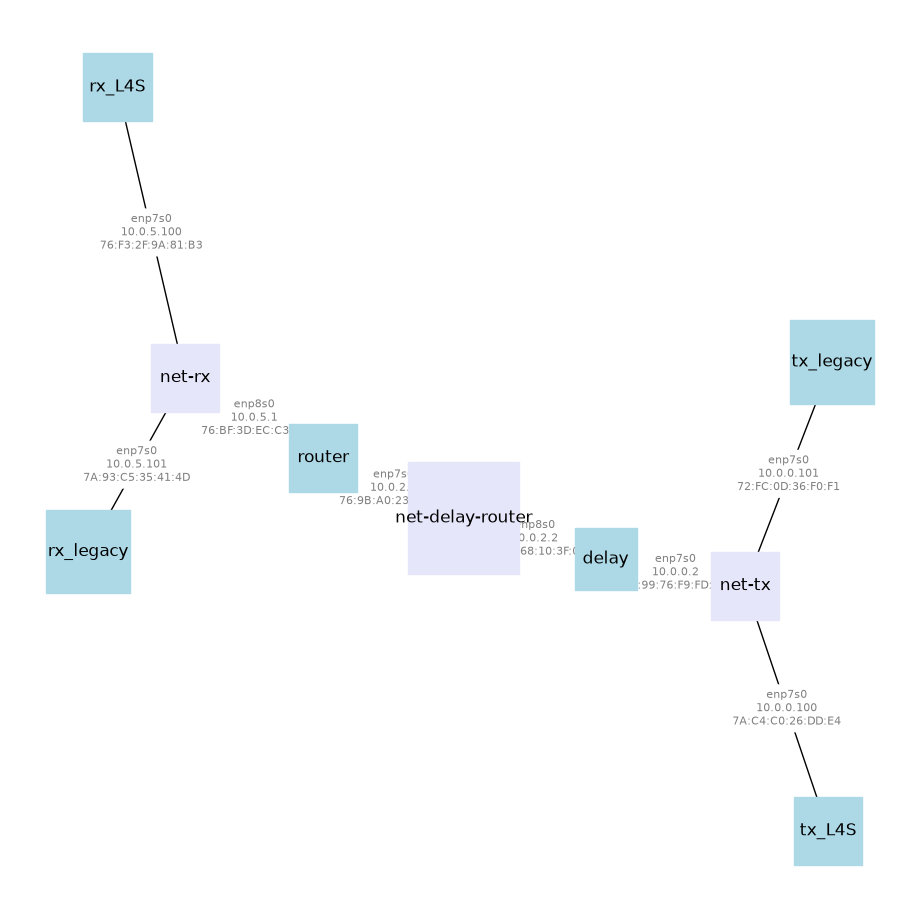

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
plt.figure(figsize=(len(nodes),len(nodes)))
G = nx.Graph()
G.add_nodes_from(nodes)
G.add_edges_from(edges)
pos = nx.spring_layout(G)
nx.draw(G, pos, node_shape='s',
        node_color=[n[1]['color'] for n in nodes],
        node_size=[len(n[0])*400 for n in nodes],
        with_labels=True);
nx.draw_networkx_edge_labels(G,pos,
                             edge_labels=nx.get_edge_attributes(G,'label'),
                             font_color='gray',  font_size=8, rotate=False);

### Log into resources

Now, we are finally ready to log in to our resources over SSH! Run the following cells, and observe the table output - you will see an SSH command for each of the resources in your topology.

In [ ]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
slice_info = [{'Name': n.get_name(), 'SSH command': n.get_ssh_command()} for n in slice.get_nodes()]
pd.DataFrame(slice_info).set_index('Name')

Now, you can open an SSH session on any of the resources as follows:

-   in Jupyter, from the menu bar, use File \> New \> Terminal to open a new terminal.
-   copy an SSH command from the table, and paste it into the terminal. (Note that each SSH command is a single line, even if the display wraps the text to a second line! When you copy and paste it, paste it all together.)

You can repeat this process (open several terminals) to start a session on each resource. Each terminal session will have a tab in the Jupyter environment, so that you can easily switch between them.

## We have configured our nodes. Now, we can design and start our experiments.

### Execute Experiment

The experiments use MGEN, UDP Prague, and socat on `tx_L4S`, `tx_legacy`, `rx_L4S`, and `rx_legacy`. Install them first, as described under **Endpoint Software** in the README.

In [ ]:
# nodes and instances

tx_L4S_node = slice.get_node(name="tx_L4S")
tx_legacy_node = slice.get_node(name="tx_legacy")
rx_L4S_node = slice.get_node(name="rx_L4S")
rx_legacy_node = slice.get_node(name="rx_legacy")
delay_node = slice.get_node(name="delay")
router_node = slice.get_node(name="router")
# interfaces

tx_L4S_egress_iface  = tx_L4S_node.get_interface(network_name = "net-tx")
tx_legacy_egress_iface  = tx_legacy_node.get_interface(network_name = "net-tx")

delay_ingress_tx_iface  = delay_node.get_interface(network_name = "net-tx")
delay_egress_iface  = delay_node.get_interface(network_name = "net-delay-router")
delay_ingress_tx_name = delay_ingress_tx_iface.get_device_name()
delay_egress_name = delay_egress_iface.get_device_name()

router_ingress_iface  = router_node.get_interface(network_name = "net-delay-router")
router_egress_iface  = router_node.get_interface(network_name = "net-rx")
router_egress_name  = router_egress_iface.get_device_name()


rx_L4S_ingress_iface  = rx_L4S_node.get_interface(network_name = "net-rx")
rx_legacy_ingress_iface  = rx_legacy_node.get_interface(network_name = "net-rx")

In [ ]:
# generate full factorial experiment
import itertools
import math


# exp_factors define our experiment factors.

# IMPORTANT THINGS TO CONSIDER:
    # For DualPI2, on the router, you need to use the Prague kernel and configure DualPI2.
    # On L4S senders, you can use Prague and L4S-compatible BBRv2 with Prague kernel with AccECN enabled.
    # On classic senders, you can use CUBIC, BBRv1, BBRv2, BBRv3 depending on the kernel installed.
    # Each experiment runs one MGEN app on tx_L4S and one MGEN app on tx_legacy simultaneously.
    # The loop iterates over all combinations of (app_tx_L4S x app_tx_legacy x other factors x trials).

exp_factors = {
    'n_bdp': [8],              # n x bandwidth delay product (BDP)
    'btl_capacity': [100],     # in Mbps
    'base_rtt': [30],          # in ms
    'aqm': ['DualPI2'],
    'ecn_threshold': [15],      # in ms
    'tx_L4S_ecn': [3],        # 0: noecn, 1: ecn, 3: accecn
    'tx_legacy_ecn': [0],     # 0: noecn, 1: ecn
    'rx_L4S_ecn': [3],        # 0: noecn, 1: ecn, 3: accecn
    'rx_legacy_ecn': [0],     # 0: noecn, 1: ecn
    'cc_tx_L4S': ["prague"],   # prague, bbr2
    'cc_tx_legacy': ["cubic","bbr1"], # Figure 1; add "bbr3" for BBRv3 (bbr2 needs the 5.13.12 kernel)
    # --- MGEN app config ---
    # App types: 'gamer', 'call', 'streaming', 'updates'
    # Protocols: 'TCP', 'UDP', 'PRAGUE'
    #'app_tx_L4S': ['file_transfer'],         # app type(s) for L4S sender
    'app_tx_L4S': ['streaming','file_transfer','call'],
    'app_tx_legacy': ['updates'],        # app type(s) for legacy sender
    'proto_tx_L4S': ['TCP', 'PRAGUE'],  # protocol for L4S flows: TCP Prague for streaming and file transfer, UDP Prague for the call
    'proto_tx_legacy': ['TCP'],          # protocol for legacy flows
    'trial': [1,2,3,4,5]
}

# Per-app MGEN parameters. L4S uses 5xxx ports, legacy uses 6xxx to avoid collisions.
mgen_app_params = {
    'gamer': {
        'mbps': 0.256, 'frame_ms': 20, 'pkt_bytes': 500, 'count': 1,
        'base_port_L4S': 5001, 'base_port_legacy': 6001,
    },
    'call': {
        'mbps': 5.0, 'frame_ms': 20, 'pkt_bytes': 1200, 'count': 5,
        'base_port_L4S': 5101, 'base_port_legacy': 6101,
    },

    'streaming': {
    # VoD chunk model
    'chunk_s': 2.0,             # chunk playback duration
    'encoding_mbps': 10.0,      # representation bitrate (used to compute chunk size)
    'pkt_bytes': 1448,          # message size used by MGEN
    'pps': 10000,               # very high => "as fast as TCP allows" (not app-limited)
    'queue': -1,              # >= one chunk worth of messages (can also use -1)
    'count': 5,                 # number of parallel VoD streams
    'video_len_s': 60.0,   # seconds of video content (e.g., 60s = 30 chunks if chunk_s=2)
    'base_port_L4S': 5201,
    'base_port_legacy': 6201
    },

    'updates': {
        'pkt_rate': 10000, 'pkt_bytes': 1448, 'streams': 1, 'count': 5,
        'base_port_L4S': 5301, 'base_port_legacy': 6301,
    },

    'file_transfer': {
    'file_mb': 100.0,          # file size per flow
    'pkt_bytes': 1448,
    'pps': 10000,              # high => not app-limited
    'count': 5,                # number of parallel transfers
    'queue': -1,
    'base_port_L4S': 5401,
    'base_port_legacy': 6401}

}

tcpinfo_window = 0.1   # TCPINFO/PRAGUEINFO reporting window (seconds)
d = 120                # experiment duration in seconds (streaming and call)
d_file_transfer_max = 3600  # file transfer runs end when the transfers finish; the bulk flows stop at this time at the latest

factor_names = [k for k in exp_factors]
factor_lists = list(itertools.product(*exp_factors.values()))

exp_lists = []
seen_combinations = set()

for factor_l in factor_lists:
    temp_dict = dict(zip(factor_names, factor_l))

    legacy_cc = temp_dict['cc_tx_legacy']

    if legacy_cc == "cubic":
        print("okay")
    #    if not (temp_dict['tx_legacy_ecn'] == 1 and temp_dict['rx_legacy_ecn'] == 1):
    #        continue
    elif legacy_cc in ("bbr1", "bbr"):
        if not (
            (temp_dict['tx_legacy_ecn'] == 0 and temp_dict['rx_legacy_ecn'] == 0) or
            (temp_dict['tx_legacy_ecn'] == 1 and temp_dict['rx_legacy_ecn'] == 1)):
            continue

    # the call runs over UDP Prague (PRAGUE), streaming and file transfer over TCP Prague (TCP)
    if (temp_dict['app_tx_L4S'] == 'call') != (temp_dict['proto_tx_L4S'] == 'PRAGUE'):
        continue

    if temp_dict['n_bdp'] * temp_dict['base_rtt'] >= temp_dict['ecn_threshold']:

        if temp_dict['aqm'] == 'FIFO':
            del temp_dict['ecn_threshold']

        fs = frozenset(temp_dict.items())

        if fs not in seen_combinations:
            seen_combinations.add(fs)
            exp_lists.append(temp_dict)

print("Number of experiments:", len(exp_lists))
for i, exp in enumerate(exp_lists):
    print(f"  {i+1}. L4S={exp['app_tx_L4S']}/{exp['proto_tx_L4S']} vs Legacy={exp['app_tx_legacy']}/{exp['proto_tx_legacy']} trial={exp['trial']}")


In [ ]:
# ============================================================
# MGEN script generation helpers (runs locally in notebook)
# ============================================================
# These functions generate MGEN .mgn script content and receiver
# shell commands.  Scripts are generated in-memory, then uploaded
# to remote nodes via heredoc.

import math

def _format_on(t, fid, proto, dst_ip, port, pps, pkt_size):
    return f"{t:<8.3f}ON  {fid} {proto} DST {dst_ip}/{port} PERIODIC [{pps} {pkt_size}]"

# def _format_off(t, fid):
#     return f"{t:<8.3f}OFF {fid}"

def _format_off(t, fid):
    return f"{t:.3f}  OFF {fid}"

def _format_mod(t, fid, pps, pkt_size):
    return f"{t:<8.3f}MOD {fid} PERIODIC [{pps} {pkt_size}]"

def _format_mod_count(t, fid, count):
    return f"{t:<8.3f}MOD {fid} COUNT {count}"


def generate_mgen_script(app_type, proto, dst_ip, duration, base_port,
                         params, tcpinfo_win=1.0):
    """Generate a standalone MGEN .mgn script string for one app type.

    Returns (script_text, list_of_ports_used)
    """
    proto = proto.upper()
    needs_tcpinfo = proto in ("TCP", "PRAGUE")
    lines = []
    ports = []

    lines.append(f"# Standalone MGEN script: {app_type} ({proto})")
    lines.append(f"# DST: {dst_ip}, duration: {duration}s")
    lines.append("")

    queue = params.get('queue', None)
    if queue is not None:
        lines.append(f"QUEUE {queue}")
        lines.append("")

    if needs_tcpinfo:
        lines.append(f"TCPINFO {tcpinfo_win}")
        lines.append("")

    fid = 1
    p = params

    if app_type == 'gamer':
        if proto == "TCP":
            pps = max(1, int(round(1000.0 / p['frame_ms'])))
            pkt_size = max(200, int(round(p['mbps'] * 1_000_000 / 8 / pps)))
            pkt_size = min(pkt_size, 8192)
        else:
            pkt_size = p['pkt_bytes']
            pps = max(1, int(round(p['mbps'] * 1_000_000 / 8 / pkt_size)))

        for i in range(p['count']):
            port = base_port + i
            ports.append(port)
            lines.append(_format_on(0.0, fid, proto, dst_ip, port, pps, pkt_size))
            fid += 1
        for i in range(1, fid):
            lines.append(_format_off(duration, i))

    elif app_type == 'call':
        if proto == "TCP":
            pps = max(1, int(round(1000.0 / p['frame_ms'])))
            pkt_size = max(200, int(round(p['mbps'] * 1_000_000 / 8 / pps)))
            pkt_size = min(pkt_size, 8192)
        else:
            pkt_size = p['pkt_bytes']
            pps = max(1, int(round(p['mbps'] * 1_000_000 / 8 / pkt_size)))

        for i in range(p['count']):
            port = base_port + i
            ports.append(port)
            lines.append(_format_on(0.0, fid, proto, dst_ip, port, pps, pkt_size))
            fid += 1
        for i in range(1, fid):
            lines.append(_format_off(duration, i))


    elif app_type == 'streaming':
        # VoD chunk model: fixed-size chunk every chunk_s seconds
        # Requires cumulative COUNT semantics on MOD (your Option 1 patch),
        # so that each MOD adds another chunk worth of bytes instead of resetting.
        pkt_size = p['pkt_bytes']
        chunk_s = float(p.get('chunk_s', 2.0))
        period_s = float(p.get('period_s', chunk_s))   # usually same as chunk_s
        enc_mbps = float(p.get('encoding_mbps', 10.0))

        # Compute chunk size (bytes) then convert to MGEN "messages" count
        chunk_bytes = int(round(enc_mbps * 1_000_000 / 8.0 * chunk_s))
        chunk_pkts = int(math.ceil(chunk_bytes / pkt_size))

        pps = int(p.get('pps', 50000))  # high => not app-limited
        #num_reqs = int(math.ceil(duration / period_s))  # how many chunk requests occur within duration
        video_len_s = float(p.get('video_len_s', duration))          # default: same as experiment
        num_reqs = int(math.ceil(video_len_s / period_s))            # requests only for video content

        # (Optional) per-flow queue for transport blocking behavior
        # You can set queue per-stream here. Note: QUEUE is global in script, so only add once.
        # We'll rely on the 'queue' param at the top of generate_mgen_script() (see note below).

        for i in range(p['count']):
            port = base_port + i
            ports.append(port)

            # Start flow and request chunk #1 immediately
            lines.append(_format_on(0.0, fid, proto, dst_ip, port, pps, pkt_size) + f" COUNT {chunk_pkts}")

            # Request additional chunks periodically
            for k in range(1, num_reqs):
                t_req = round(k * period_s, 3)
                if t_req >= duration:
                    break
                # Cumulative chunk request (requires your MOD+COUNT patch)
                lines.append(_format_mod_count(t_req, fid, chunk_pkts))

            lines.append(_format_off(duration, fid))
            fid += 1


    elif app_type == 'file_transfer':
    # Finite file transfer: send one file as fast as possible, then stop automatically.
        pkt_size = p['pkt_bytes']
        pps = int(p.get('pps', 50000))
        file_mb = float(p.get('file_mb', 100.0))
        file_bytes = int(round(file_mb * 1024 * 1024))   # MiB-style
        file_pkts = int(math.ceil(file_bytes / pkt_size))

        for i in range(p['count']):
            port = base_port + i
            ports.append(port)
            lines.append(
                _format_on_count_off(0.0, fid, proto, dst_ip, port, pps, pkt_size, file_pkts)
            )
            fid += 1

    elif app_type == 'updates' or app_type == 'updates-v2':
        pps = p['pkt_rate']
        pkt_size = p['pkt_bytes']
        streams = p.get('streams', 4)
        count = p.get('count', 1)

        for i in range(count):
            for s in range(streams):
                port = base_port + i * streams + s
                ports.append(port)
                lines.append(_format_on(0.0, fid, proto, dst_ip, port, pps, pkt_size))
                fid += 1
        for i in range(1, fid):
            lines.append(_format_off(duration, i))

    lines.append("")
    return "\n".join(lines), ports


def generate_receiver_cmds(ports, proto, listen_ip, exp_name, side):
    """Generate shell commands to start receiver sinks for the given ports/proto.

    Args:
        ports: list of port numbers
        proto: "TCP", "UDP", or "PRAGUE"
        listen_ip: IP address the receiver binds to
        exp_name: experiment name for output file naming
        side: "L4S" or "legacy" for output file naming
    """
    proto = proto.upper()
    cmds = []
    if proto == "TCP":
        for p in sorted(ports):
            cmds.append(
                f"setsid -f socat -u TCP-LISTEN:{p},fork,reuseaddr OPEN:/dev/null "
                f">/dev/null 2>&1 </dev/null"
            )
    elif proto == "PRAGUE":
        for p in sorted(ports):
            json_out = f"{exp_name}_rx_{side}_port{p}.json"
            cmds.append(
                f"setsid -f ./udp_prague_receiver -a {listen_ip} -i 100000 -p {p} -j {json_out} "
                f">/dev/null 2>&1 </dev/null"
            )
    else:  # UDP
        for p in sorted(ports):
            cmds.append(
                f"setsid -f socat -u UDP-RECVFROM:{p},fork OPEN:/dev/null "
                f">/dev/null 2>&1 </dev/null"
            )
    return "\n".join(cmds)


def generate_cleanup_cmds():
    """Shell commands to kill leftover receiver processes."""
    return "killall socat 2>/dev/null; killall mgen 2>/dev/null; killall udp_prague_receiver 2>/dev/null; true"


def build_exp_name(exp):
    """Build a unique experiment output name from experiment factors."""
    return (
        f"{exp['app_tx_L4S']}-{exp['proto_tx_L4S']}"
        f"_{exp['app_tx_legacy']}-{exp['proto_tx_legacy']}"
        f"_{exp['cc_tx_L4S']}_{exp['cc_tx_legacy']}"
        f"_{exp['aqm']}_{exp['n_bdp']}_{exp.get('ecn_threshold', 'none')}"
        f"_{exp['base_rtt']}ms_{exp['btl_capacity']}Mbps"
        f"_t{exp['trial']}"
    )

def upload_script_to_node(node, filename, content):
    """Upload a script string to a remote node using heredoc."""
    cmd = f"cat > {filename} << 'MGENEOF'\n{content}\nMGENEOF"
    node.execute(cmd)

def _format_on_count_off(t, fid, proto, dst_ip, port, pps, pkt_size, count):
    return (
        f"{t:<8.3f}ON  {fid} {proto} DST {dst_ip}/{port} "
        f"PERIODIC [{pps} {pkt_size}] COUNT {count},off"
    )

print("MGEN helper functions loaded.")
print(f"  Available apps: {list(mgen_app_params.keys())}")

In [ ]:
# ============================================================
# MGEN Experiment Loop
# ============================================================
# For each experiment combination:
#   1. Generate MGEN scripts locally
#   2. Upload to sender nodes
#   3. Start receiver sinks on rx nodes
#   4. Start DualPI2 logging on router
#   5. Run MGEN senders (L4S in background thread, legacy blocking)
#   6. Cleanup

import time

em = [delay_ingress_tx_name, delay_egress_name]

for exp_idx, exp in enumerate(exp_lists):

    exp_name = build_exp_name(exp)

    # --- Check if results already exist (stop/resume support) ---
    file_check = f"{exp_name}_tx_legacy.log"
    stdout_check, stderr_check = tx_legacy_node.execute("ls " + file_check, quiet=True)

    if len(stdout_check):
        print(f"[{exp_idx+1}/{len(exp_lists)}] Already have {exp_name}, skipping")
        continue

    print(f"[{exp_idx+1}/{len(exp_lists)}] Running: {exp_name}")

    cc_tx_legacy = exp['cc_tx_legacy']
    if cc_tx_legacy == 'bbr3':
        cc_tx_legacy = "bbr"

    # --- Configure CC and ECN on all nodes ---
    tx_L4S_node.execute("sudo modprobe tcp_" + exp['cc_tx_L4S'])
    tx_L4S_node.execute("sudo sysctl -w net.ipv4.tcp_congestion_control=" + exp['cc_tx_L4S'])
    tx_L4S_node.execute("sudo sysctl -w net.ipv4.tcp_ecn=" + str(exp['tx_L4S_ecn']))

    tx_legacy_node.execute("sudo modprobe tcp_" + cc_tx_legacy)
    tx_legacy_node.execute("sudo sysctl -w net.ipv4.tcp_congestion_control=" + cc_tx_legacy)
    tx_legacy_node.execute("sudo sysctl -w net.ipv4.tcp_ecn=" + str(exp['tx_legacy_ecn']))

    rx_legacy_node.execute("sudo modprobe tcp_" + cc_tx_legacy)
    rx_legacy_node.execute("sudo sysctl -w net.ipv4.tcp_congestion_control=" + cc_tx_legacy)
    rx_legacy_node.execute("sudo sysctl -w net.ipv4.tcp_ecn=" + str(exp['rx_legacy_ecn']))

    rx_L4S_node.execute("sudo sysctl -w net.ipv4.tcp_congestion_control=" + exp['cc_tx_L4S'])
    rx_L4S_node.execute("sudo sysctl -w net.ipv4.tcp_ecn=" + str(exp['rx_L4S_ecn']))

    # --- Configure delay ---
    for e in em:
        delay_node.execute("sudo tc qdisc replace dev {iface} root netem delay {owd}ms limit 1000000".format(iface=e, owd=exp['base_rtt'] / 2))

    # --- Configure AQM on router ---
    btl_limit = int(1000 * exp['n_bdp'] * exp['btl_capacity'] * exp['base_rtt'] / 8)
    packet_number = int(btl_limit / 1500) + 1

    router_node.execute(
        "sudo tc qdisc del dev {iface} root; "
        "sudo tc qdisc replace dev {iface} root handle 1: htb default 3; "
        "sudo tc class add dev {iface} parent 1: classid 1:3 htb rate {cap}mbit".format(
            iface=router_egress_name, cap=exp['btl_capacity']))

    aqm_cmds = {
        'FIFO': "bfifo limit {b}",
        'single_queue_FQ': "fq limit {pl} flow_limit {pl} orphan_mask 0 ce_threshold {t}ms",
        #'Codel': "codel limit {pl} target {t}ms interval 100ms ecn",
        'Codel': "codel limit {pl}",
        'Codel_drop': "codel limit {pl} target {t}ms interval 100ms noecn",
        'FQ': "fq limit {pl} flow_limit {pl} ce_threshold {t}ms",
        'FQ_Codel': "fq_codel limit {pl} target {t}ms interval 100ms ecn",
        #'FQ_Codel_L4S': "fq_codel limit {pl} target {t}ms interval 100ms ecn ce_threshold 1ms ce_threshold_selector 0x01/0x01",
        'FQCodel-L4S': "fq_codel limit {pl} ce_threshold 1ms ce_threshold_selector 0x01/0x01",
        'pie_drop': "pie limit {pl} target {t}ms noecn",
        'pie': "pie limit {pl}",
        #'DualPI2': "dualpi2 limit {pl} target {t}ms"}
        'DualPI2': "dualpi2 limit {pl}"}

    aqm_cmd = aqm_cmds[exp['aqm']].format(b=btl_limit, pl=packet_number, t=exp.get('ecn_threshold', 0))

    router_node.execute("sudo tc qdisc replace dev {iface} parent 1:3 handle 3: {cmd}".format(iface=router_egress_name, cmd=aqm_cmd))

    print("router is done.")

    # --- Cleanup any leftover processes ---
    rx_L4S_node.execute(generate_cleanup_cmds())
    rx_legacy_node.execute(generate_cleanup_cmds())
    tx_L4S_node.execute("killall mgen 2>/dev/null; true")
    tx_legacy_node.execute("killall mgen 2>/dev/null; true")

    # --- Generate MGEN scripts locally ---
    app_L4S = exp['app_tx_L4S']
    proto_L4S = exp['proto_tx_L4S']
    params_L4S = mgen_app_params[app_L4S]
    port_L4S = params_L4S['base_port_L4S']

    # file transfer runs end when the transfers finish, so their bulk flows get the long cap
    dur = d_file_transfer_max if app_L4S == 'file_transfer' else d

    script_L4S, ports_L4S = generate_mgen_script(app_L4S, proto_L4S, "10.0.5.100", dur, port_L4S, params_L4S, tcpinfo_window)

    app_legacy = exp['app_tx_legacy']
    proto_legacy = exp['proto_tx_legacy']
    params_legacy = mgen_app_params[app_legacy]
    port_legacy = params_legacy['base_port_legacy']

    script_legacy, ports_legacy = generate_mgen_script(app_legacy, proto_legacy, "10.0.5.101", dur, port_legacy, params_legacy, tcpinfo_window)

    # --- Upload MGEN scripts to sender nodes ---
    mgn_file_L4S = f"{exp_name}_tx_L4S.mgn"
    mgn_file_legacy = f"{exp_name}_tx_legacy.mgn"

    upload_script_to_node(tx_L4S_node, mgn_file_L4S, script_L4S)
    upload_script_to_node(tx_legacy_node, mgn_file_legacy, script_legacy)

    print(f"  Uploaded: {mgn_file_L4S} ({app_L4S}/{proto_L4S}, ports {ports_L4S})")
    print(f"  Uploaded: {mgn_file_legacy} ({app_legacy}/{proto_legacy}, ports {ports_legacy})")


    WORKDIR = "/home/ubuntu/L4S_Project/udp_prague"

    # # --- Start receiver sinks ---
    # rx_L4S_cmds = generate_receiver_cmds(ports_L4S, proto_L4S)
    # rx_legacy_cmds = generate_receiver_cmds(ports_legacy, proto_legacy)

    # --- Start receiver sinks ---
    rx_L4S_cmds = generate_receiver_cmds(ports_L4S, proto_L4S, "10.0.5.100", exp_name, "L4S")
    rx_legacy_cmds = generate_receiver_cmds(ports_legacy, proto_legacy, "10.0.5.101", exp_name, "legacy")

    # rx_L4S_node.execute(f"cd {WORKDIR} && {rx_L4S_cmds}")
    # rx_legacy_node.execute(f"cd {WORKDIR} && {rx_legacy_cmds}")

    rx_L4S_node.execute(f"cd {WORKDIR} && {rx_L4S_cmds}")
    rx_legacy_node.execute(f"cd {WORKDIR} && {rx_legacy_cmds}")

    # rx_L4S_node.execute(rx_L4S_cmds)
    # rx_legacy_node.execute(rx_legacy_cmds)
    time.sleep(1)

    # --- Start DualPI2 logging on router ---
    router_log = f"{exp_name}_dualpi2"
    #router_node.execute_thread("./dualpi2.sh {logfile}.log {duration} {interface}".format(logfile=router_log, duration=d + 3, interface=router_egress_name))

    #router_node.execute_thread("sudo ./collect_dualpi2_trace.sh {logfile}.log {duration}".format(logfile=router_log, duration=d + 3))

    # --- Run MGEN senders ---
    log_L4S = f"{exp_name}_tx_L4S.log"
    log_legacy = f"{exp_name}_tx_legacy.log"

    MGEN_BIN = "/home/ubuntu/L4S_Project/mgen/makefiles/mgen"



    #rx_legacy_node.execute("iperf3 -s -1 -p 6401 -D")


    if app_L4S == 'file_transfer':
        # The run ends when the transfers finish: the L4S MGEN exits once its COUNT-limited flows are done,
        # so the L4S sender is blocking and the bulk (legacy) sender is stopped afterwards.
        print("running sender2 (bulk, background)")
        tx_legacy_node.execute_thread(f"sleep 1; {MGEN_BIN} input {mgn_file_legacy} output {log_legacy}")
        print("running sender1 (file transfer, until it finishes)")
        stdout, stderr = tx_L4S_node.execute(f"sleep 1; timeout {d_file_transfer_max + 300} {MGEN_BIN} input {mgn_file_L4S} output {log_L4S}")
        tx_legacy_node.execute("killall mgen 2>/dev/null; true")
        time.sleep(5)
    else:
        print("running sender1")

        # L4S sender runs in background thread
        tx_L4S_node.execute_thread(f"sleep 1; {MGEN_BIN} input {mgn_file_L4S} output {log_L4S}")

        print("running sender2")

        # Legacy sender is blocking (we wait for it to finish)
        stdout, stderr = tx_legacy_node.execute(f"sleep 1; {MGEN_BIN} input {mgn_file_legacy} output {log_legacy}")

        # Wait a few seconds for L4S sender thread to also finish
        time.sleep(5)

    # --- Cleanup receiver sinks ---
    rx_L4S_node.execute(generate_cleanup_cmds())
    rx_legacy_node.execute(generate_cleanup_cmds())

    print(f"  Done: {exp_name}")
    print(f"  Output: {log_L4S}, {log_legacy}")
    print()

print("=" * 60)
print(f"All {len(exp_lists)} experiments finished.")

### Analyze the results

The scripts in `utils/` compute the Figure 1 metrics on the nodes. The results are then downloaded to `Experiment_Data/motivation-experiments/` (replacing the published results in your copy of the repository) and plotted with `plotting-scripts/plot_fig1.py`.

In [ ]:
# upload the analysis scripts
tx_L4S_node.upload_file("utils/analyze_streaming.py", "/home/ubuntu/analyze_streaming.py")
tx_L4S_node.upload_file("utils/analyze_file_transfer.py", "/home/ubuntu/analyze_file_transfer.py")
rx_L4S_node.upload_file("utils/prague_receiver_stats.py", "/home/ubuntu/prague_receiver_stats.py")

In [ ]:
# video streaming: rebuffering, from the L4S sender's MGEN logs
tx_L4S_node.execute("mkdir -p streaming && cp streaming-*_tx_L4S.log streaming/ && cd streaming && python3 ../analyze_streaming.py -d . --chunk-duration 2 --chunk-size-packets 1727 --bytes-per-packet 1448 --num-chunks 30 --timeline -o video_streaming_results_large_buffer.json")

In [ ]:
# video call: achieved rate, from the UDP Prague receiver reports
rx_L4S_node.execute("python3 prague_receiver_stats.py /home/ubuntu/L4S_Project/udp_prague --target-rate-mbps 5.0 --rtt-threshold-ms 150 --bad-rate-threshold 0.9 -o prague_receiver_agg-5-apps.json")

In [ ]:
# file transfer: flow completion time, from the L4S sender's MGEN logs
tx_L4S_node.execute("mkdir -p file_transfer && cp file_transfer-*_tx_L4S.log file_transfer/ && cd file_transfer && python3 ../analyze_file_transfer.py --count 72416 --bytes-per-packet 1448 -o file_transfer.json")

In [ ]:
# download the results to where plotting-scripts/plot_fig1.py reads them
out_dir = "Experiment_Data/motivation-experiments"
tx_L4S_node.download_file(f"{out_dir}/video_streaming_results_large_buffer.json", "/home/ubuntu/streaming/video_streaming_results_large_buffer.json")
tx_L4S_node.download_file(f"{out_dir}/file_transfer.json", "/home/ubuntu/file_transfer/file_transfer.json")
rx_L4S_node.download_file(f"{out_dir}/prague_receiver_agg-5-apps.json", "/home/ubuntu/prague_receiver_agg-5-apps.json")

In [ ]:
# Figure 1 -> Plots/fig1.pdf
!python3 plotting-scripts/plot_fig1.py